In [1]:
import yfinance as yf
import pandas as pd
import sys
from pathlib import Path
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / 'src'))
from dataloader import load_sp500_data

In [8]:
SnP = yf.download('^GSPC', start='2000-01-01', end='2025-01-01')
returns = SnP['Close'].pct_change().dropna()
returns['Close'] = SnP['Close'].dropna()
returns.head()

[*********************100%***********************]  1 of 1 completed


Ticker,^GSPC,Close
Date,,
2000-01-04,-0.038345,1399.420044
2000-01-05,0.001922,1402.109985
2000-01-06,0.000956,1403.449951
2000-01-07,0.027090,1441.469971
2000-01-10,0.011190,1457.599976


In [9]:
returns.to_csv('sp500_returns.csv')

# Data Visualisation 

In [15]:
train_data, test_data, mean, std = load_sp500_data(r'sp500_returns.csv', train_ratio=0.8)
print(train_data)

[-3.16379621  0.13307279  0.05393971 ... -0.02152441 -0.49761472
  0.2169001 ]


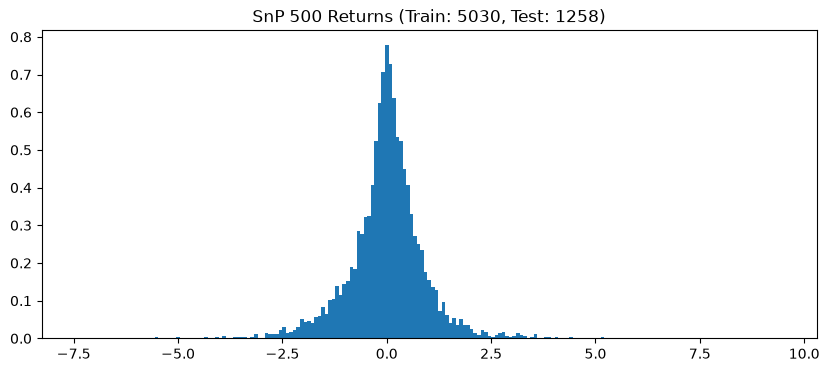

Mean: -0.005533051716232875, Std: 0.9733305367540804


In [16]:
plt.figure(figsize=(10, 4))
plt.hist(train_data, bins=199, density=True)
plt.title(f'SnP 500 Returns (Train: {len(train_data)}, Test: {len(test_data)})')
plt.savefig('../results/SnP_returns_histogram.png')
plt.show()

print(f"Mean: {train_data.mean()}, Std: {train_data.std()}")

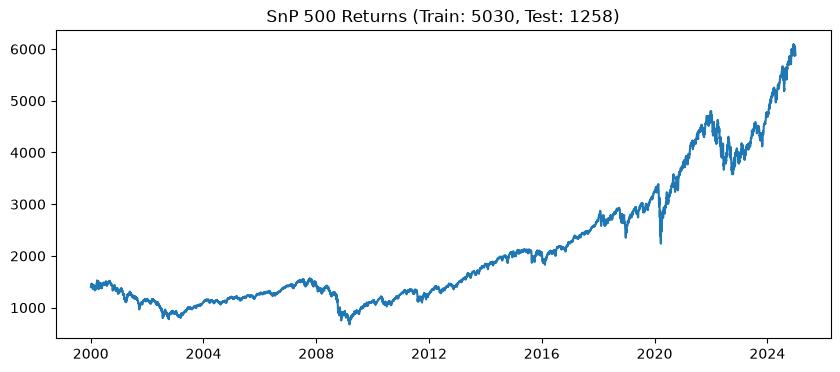

Mean: 2112.118644801715, Std: 1243.384589283714


In [18]:
plt.figure(figsize=(10, 4))
plt.plot(returns['Close'])
plt.title(f'SnP 500 Returns (Train: {len(train_data)}, Test: {len(test_data)})')
plt.savefig('../results/SnP_returns_plot.png')
plt.show()

print(f"Mean: {returns['Close'].mean()}, Std: {returns['Close'].std()}")